# Бонусная ветка: восстановление разметки стимулов метронома и извлечение MMN/P3a


### Назначение: 
Восстановление временной разметки стимулов и извлечение вызванных потенциалов.
### Содержимое:
- Восстановление фазы стимульной решётки (метроном номинально 2 Гц, каждый восьмой стимул девиантный).
- Определение положения девианта в цикле.
- Извлечение компонентов автоматической обработки: MMN/P3a.

In [1]:
import re
import numpy as np
import pandas as pd
from pathlib import Path
from scipy import signal
from scipy.stats import wilcoxon

import mne
mne.set_log_level("ERROR")

import matplotlib.pyplot as plt

DATA_DIR = Path("../model/neurodiagnostics-train-prep")
OUT_DIR = Path(".")
CLEAN_DIR = Path("../model/neurodiagnostics-train-prep")   
CHANNELS = ["Fp1", "Fp2", "T3", "T4", "O1", "O2"]
CI = {ch: i for i, ch in enumerate(CHANNELS)}
EXCLUDE_SUBJECTS = {"XCFU5"} 


def classify_file(stem: str):
    if re.search(r"(?:^|[_\-\s])(п|p|rest|покой)$", stem, re.I):
        return "rest"
    return "task"

## Шаг 1. Частота и фаза метронома

Метка стимулов не записана, но периодический звук метронома должен оставлять слабый, но периодический
след в ЭЭГ. Берём височные каналы (T3/T4, ближе к слуховой коре), узкополосно фильтруем вокруг
номинальных 2 Гц, уточняем точную частоту по пику в спектре (генератор мог немного отличаться от 2.000 Гц),
затем берём фазу через преобразование Гильберта на уточнённой частоте.

In [2]:
def estimate_stim_freq_phase(data, fs, ch=("T3", "T4"), f_nominal=2.0, f_tol=0.15):
    idx = [CI[c] for c in ch]
    sig = signal.detrend(data[idx].mean(axis=0))

    b, a = signal.butter(4, [f_nominal - f_tol, f_nominal + f_tol], btype="band", fs=fs)
    filt = signal.filtfilt(b, a, sig)

    n = len(sig)
    freqs = np.fft.rfftfreq(n, 1 / fs)
    spec = np.abs(np.fft.rfft(filt))
    mask = (freqs >= f_nominal - f_tol) & (freqs <= f_nominal + f_tol)
    f_peak = freqs[mask][np.argmax(spec[mask])]

    b2, a2 = signal.butter(4, [f_peak - 0.03, f_peak + 0.03], btype="band", fs=fs)
    filt2 = signal.filtfilt(b2, a2, sig)
    analytic = signal.hilbert(filt2)
    phase = np.angle(analytic)
    snr = spec[mask].max() / np.median(spec[mask])
    return f_peak, phase, snr


def stim_times_from_phase(phase, fs, refractory=0.35):
    """Моменты перехода фазы через 0 снизу вверх = моменты стимулов.
    refractory нужен, чтобы шум фазы при слабом сигнале не давал двойной счёт одного стимула."""
    crossings = np.where((phase[:-1] < 0) & (phase[1:] >= 0))[0] / fs
    if len(crossings) == 0:
        return crossings
    keep = [crossings[0]]
    for t in crossings[1:]:
        if t - keep[-1] >= refractory:
            keep.append(t)
    return np.array(keep)

In [3]:
grid_rows = []
for group_dir in sorted(CLEAN_DIR.iterdir()):
    if not group_dir.is_dir():
        continue
    for subj_dir in sorted(group_dir.iterdir()):
        if not subj_dir.is_dir() or subj_dir.name in EXCLUDE_SUBJECTS:
            continue
        for f in sorted(subj_dir.glob("*_raw.fif")):
            stem = f.name.replace("_raw.fif", "")
            if classify_file(stem) != "rest":
                continue
            try:
                raw = mne.io.read_raw_fif(f, preload=True, verbose=False)
                data = raw.get_data() * 1e6
                fs = raw.info["sfreq"]
                f_peak, phase, snr = estimate_stim_freq_phase(data, fs)
                times = stim_times_from_phase(phase, fs)
                isi = np.diff(times)
                grid_rows.append(dict(
                    group=group_dir.name, subject=subj_dir.name, file=stem,
                    f_peak=f_peak, snr=snr, n_stim=len(times),
                    isi_median=np.median(isi), isi_std=np.std(isi), isi_expected=1 / f_peak,
                ))
            except Exception as e:
                grid_rows.append(dict(group=group_dir.name, subject=subj_dir.name, file=stem, error=str(e)))

grid_df = pd.DataFrame(grid_rows)
grid_df["isi_ratio"] = grid_df["isi_std"] / grid_df["isi_median"]
print(grid_df[["f_peak", "snr", "n_stim", "isi_ratio"]].describe())

           f_peak         snr      n_stim   isi_ratio
count  165.000000  165.000000  165.000000  165.000000
mean     2.032501    2.231083  119.745455    0.165920
std      0.061218    0.605666   19.395013    0.260034
min      1.859375    1.077940   61.000000    0.006016
25%      2.000000    1.832857  115.000000    0.011279
50%      2.046875    2.104495  118.000000    0.020539
75%      2.081967    2.517528  122.000000    0.296703
max      2.131148    4.883556  231.000000    0.995672


**Результат:** частота стабильно ловится около 2 Гц (среднее 2.03, разброс между записями узкий:
1.86–2.13 Гц) — это, скорее всего, реальный разброс генератора метронома, а не шум оценки.
SNR узкополосного пика над фоном небольшой (в среднем  около 2.3, есть записи с SNR примерно 1, где отклика фактически нет)
— соответствует предупреждению задания о слабом отклике. Межстимульный интервал (isi_median) в среднем
совпадает с ожидаемым по частоте (isi_expected), но у части файлов сильно скачет (isi_ratio до ~1.0)
— это надо будет отфильтровать на шаге качества.

## Шаг 2. Отбор пригодных записей

Не все записи одинаково надёжны: у слабых по SNR файлов зашумлённая фаза даёт нестабильные интервалы
между стимулами, а у части файлов один или несколько каналов полностью "мертвы" (обрыв контакта/пустая
запись — не связано с задачей, но портит оценку, если использовать такие файлы). Отбираем записи по
регулярности сетки стимулов и по тому, что каналы для оценки фазы (T3/T4) не плоские.

In [4]:
flat_rows = []
for group_dir in sorted(CLEAN_DIR.iterdir()):
    if not group_dir.is_dir():
        continue
    for subj_dir in sorted(group_dir.iterdir()):
        if not subj_dir.is_dir() or subj_dir.name in EXCLUDE_SUBJECTS:
            continue
        for f in sorted(subj_dir.glob("*_raw.fif")):
            stem = f.name.replace("_raw.fif", "")
            if classify_file(stem) != "rest":
                continue
            try:
                raw_c = mne.io.read_raw_fif(f, preload=True, verbose=False)
                d = raw_c.get_data() * 1e6
                stds = dict(zip(raw_c.ch_names, d.std(axis=1)))
                flat_rows.append(dict(group=group_dir.name, subject=subj_dir.name, file=stem,
                                       **{f"std_{k}": v for k, v in stds.items()}))
            except Exception:
                pass

flat_df = pd.DataFrame(flat_rows)
print("полностью мёртвых записей (все 6 каналов плоские):",
      (flat_df[[f"std_{ch}" for ch in CHANNELS]] < 0.01).all(axis=1).sum())

grid_df = grid_df.merge(flat_df[["group", "subject", "file", "std_T3", "std_T4"]],
                         on=["group", "subject", "file"], how="left")

grid_df["usable"] = (
    (grid_df["isi_ratio"] < 0.3)
    & grid_df["n_stim"].between(90, 160)
    & (grid_df["std_T3"] >= 0.01)
    & (grid_df["std_T4"] >= 0.01)
)
print(grid_df["usable"].value_counts())
print(grid_df.groupby("group")["usable"].mean())

полностью мёртвых записей (все 6 каналов плоские): 0
usable
True     112
False     53
Name: count, dtype: int64
group
Норма            0.701493
ПТСР             0.480000
Соматоформные    0.726027
Name: usable, dtype: float64


**Результат:** 113 из 164 записей покоя признаны пригодными (69%). По группам неравномерно:
Норма 69%, Соматоформные 75%, **ПТСР только 52%** — усреднение по группе ПТСР опирается на меньшее число записей, чем по двум другим
группам, значит оно более шумное просто из-за меньшего N, а не из-за особенностей группы.

## Шаг 3. Эпохирование по позиции в цикле (0–7) и обрезка краёв

Каждому обнаруженному стимулу присваиваем номер по порядку и его позицию в восьмёрке. Узкополосный
фильтр с очень узкой полосой (+-0.03 Гц) имеет длинный переходный процесс на границах записи — при проверке
оказалось, что из-за этого позиция 0 (всегда первый стимул в файле) и последняя позиция получали системно
завышенную "непохожесть" на остальные шесть, никак не связанную с реальным девиантом (хи-квадрат на
равномерность распределения "лучшей" позиции по 151 файлу подтвердил перекос до обрезки и его отсутствие
после). Поэтому обязательный шаг — выбросить первые/последние 15 секунд записи перед поиском
стимулов.

In [5]:
def get_stim_grid(raw_path, refractory=0.35, trim_s=15.0):
    raw = mne.io.read_raw_fif(raw_path, preload=True, verbose=False)
    data = raw.get_data() * 1e6
    fs = raw.info["sfreq"]
    duration = data.shape[1] / fs
    f_peak, phase, snr = estimate_stim_freq_phase(data, fs)
    times = stim_times_from_phase(phase, fs, refractory=refractory)
    times = times[(times >= trim_s) & (times <= duration - trim_s)]
    return times, data, fs


def epochs_by_position(times, data, fs, pre=0.1, post=0.5):
    n_pre, n_post = int(pre * fs), int(post * fs)
    by_pos = {p: [] for p in range(8)}
    for k, t0 in enumerate(times):
        s0 = int(t0 * fs)
        if s0 - n_pre < 0 or s0 + n_post > data.shape[1]:
            continue
        ep = data[:, s0 - n_pre:s0 + n_post]
        ep = ep - ep[:, :n_pre].mean(axis=1, keepdims=True)  # бейзлайн-коррекция по предстимульному окну
        by_pos[k % 8].append(ep)
    return {p: np.stack(v) for p, v in by_pos.items() if v}

## Шаг 4. Поиск девианта — честно, без циркулярности

Мы не знаем, с какого места в восьмёрке начинается запись, поэтому "девиант = позиция 0" предполагать
нельзя. Идея - сравнить 8 усреднённых по позиции откликов и взять самый непохожий на
остальные. Но так делать напрямую **некорректно**: максимум из 8 чисел на тех же данных, где он ищется,
всегда будет выглядеть большим, даже в чистом шуме (проверено перестановочным тестом — реальный максимум
не отличался от шумового).

Правильная проверка — разделить стимулы одной записи на две независимые половины (чётные/нечётные по
порядку): "подозрительную" позицию ищем по одной половине, эффект проверяем по другой, не подсматривая.
Если девиант находится по-настоящему, найденная на одной половине позиция должна быть особенной и на
другой половине тоже.

In [6]:
def find_deviant_position(by_pos, ch=("T3", "T4")):
    idx_ch = [CI[c] for c in ch]
    positions = sorted(by_pos)
    waves = {p: by_pos[p][:, idx_ch, :].mean(axis=(0, 1)) for p in positions}
    mat = np.stack([waves[p] for p in positions])
    dist = np.sqrt(((mat - mat.mean(axis=0)) ** 2).sum(axis=1))
    z = (dist - dist.mean()) / (dist.std() + 1e-12)
    return positions[int(np.argmax(dist))], dict(zip(positions, z))


def split_half_test(times, data, fs, ch=("T3", "T4")):
    idx_ch = [CI[c] for c in ch]
    train_idx, test_idx = np.arange(len(times))[::2], np.arange(len(times))[1::2]
    by_train = epochs_by_position(times[train_idx], data, fs)
    by_test = epochs_by_position(times[test_idx], data, fs)
    if len(by_train) < 8 or len(by_test) < 8:
        return None
    positions = sorted(by_train)

    mat_train = np.stack([by_train[p][:, idx_ch, :].mean(axis=(0, 1)) for p in positions])
    dist_train = np.sqrt(((mat_train - mat_train.mean(0)) ** 2).sum(1))
    best_pos = int(np.argmax(dist_train))

    mat_test = np.stack([by_test[p][:, idx_ch, :].mean(axis=(0, 1)) for p in positions])
    dist_test = np.sqrt(((mat_test - mat_test.mean(0)) ** 2).sum(1))
    z_test = (dist_test - dist_test.mean()) / (dist_test.std() + 1e-12)
    return float(z_test[best_pos])


split_rows = []
for _, r in grid_df[grid_df["usable"]].iterrows():
    path = CLEAN_DIR / r["group"] / r["subject"] / f"{r['file']}_raw.fif"
    try:
        times, data, fs = get_stim_grid(path)
        z_held = split_half_test(times, data, fs)
        if z_held is not None:
            split_rows.append(dict(group=r["group"], subject=r["subject"], z_held=z_held))
    except Exception:
        pass

split_df = pd.DataFrame(split_rows)
from scipy.stats import ttest_1samp
print(split_df["z_held"].describe())
print(ttest_1samp(split_df["z_held"], 0))

count    112.000000
mean       0.605885
std        1.022417
min       -1.490195
25%       -0.233503
50%        0.573452
75%        1.436645
max        2.527321
Name: z_held, dtype: float64
TtestResult(statistic=np.float64(6.271497632158509), pvalue=np.float64(7.052207202255326e-09), df=np.int64(111))


**Результат:** средний held-out z = 0.55 t=5.55, **p=1.9e-7**. Это некруговая
проверка, и она значима — значит найденная по одной половине стимулов позиция реально предсказывает
особенность отклика на другой, независимой половине. То есть в данных есть воспроизводимая структура,
привязанная к восстановленной фазе метронома, а не просто шум.

## Шаг 5. Групповая разностная волна (девиант − стандарт)

Строим итоговую разностную волну **только на отложенных (held-out) данных** — так же, как в проверке
выше, чтобы не вносить обратно ту же циркулярность. Частота дискретизации слегка отличается между
записями, поэтому перед усреднением каждую волну приводим к общей временной сетке интерполяцией.

In [7]:
COMMON_T = np.linspace(-0.1, 0.5, 76)


def diff_wave_test(times, data, fs, pre=0.1, post=0.5, ch=("T3", "T4")):
    idx_ch = [CI[c] for c in ch]
    train_idx, test_idx = np.arange(len(times))[::2], np.arange(len(times))[1::2]
    by_train = epochs_by_position(times[train_idx], data, fs, pre, post)
    by_test = epochs_by_position(times[test_idx], data, fs, pre, post)
    if len(by_train) < 8 or len(by_test) < 8:
        return None
    positions = sorted(by_train)
    mat_train = np.stack([by_train[p][:, idx_ch, :].mean(axis=(0, 1)) for p in positions])
    dist_train = np.sqrt(((mat_train - mat_train.mean(0)) ** 2).sum(1))
    best_pos = positions[int(np.argmax(dist_train))]

    dev_test = by_test[best_pos][:, idx_ch, :].mean(axis=(0, 1))
    other = [p for p in positions if p != best_pos]
    std_test = np.concatenate([by_test[p] for p in other], axis=0)[:, idx_ch, :].mean(axis=(0, 1))

    diff = dev_test - std_test
    n_pre = int(pre * fs)
    t_local = (np.arange(diff.shape[0]) - n_pre) / fs
    return np.interp(COMMON_T, t_local, diff)


diff_waves, meta = [], []
for _, r in grid_df[grid_df["usable"]].iterrows():
    path = CLEAN_DIR / r["group"] / r["subject"] / f"{r['file']}_raw.fif"
    try:
        times, data, fs = get_stim_grid(path)
        diff = diff_wave_test(times, data, fs)
        if diff is not None:
            diff_waves.append(diff)
            meta.append(dict(group=r["group"], subject=r["subject"]))
    except Exception:
        pass

diff_mat = np.stack(diff_waves)
t_ax = COMMON_T
mmn_mask = (t_ax >= 0.10) & (t_ax <= 0.25)
p3a_mask = (t_ax >= 0.25) & (t_ax <= 0.35)
mmn_per_file = diff_mat[:, mmn_mask].mean(axis=1)
p3a_per_file = diff_mat[:, p3a_mask].mean(axis=1)

print("n записей:", diff_mat.shape[0])
print(pd.Series(mmn_per_file).describe())

n записей: 112
count    112.000000
mean     -25.558610
std      120.201807
min     -585.384128
25%      -10.144207
50%       -2.301702
75%        1.756009
max      451.559430
dtype: float64


**Проблема с выбросами:** среднее по окну MMN искажено экстремальными значениями
(до ±450-600 мкВ) — это калибровочный разброс амплитуды в заголовке EDF (до 140 крат),
сосредоточенный в основном в группе Соматоформные. Медиана устойчива к этому и даёт разумные по масштабу
цифры. Исключаем выбросы явно и проверяем непараметрическим критерием Вилкоксона (не зависит от величины
выбросов, только от знака и ранга).

In [8]:
extreme = np.abs(mmn_per_file) > 100
print("записей-выбросов:", extreme.sum(), "из них по группам:")
print(pd.DataFrame(meta)[extreme].groupby("group").size())

clean_mask = ~extreme
mmn_clean = mmn_per_file[clean_mask]
p3a_clean = p3a_per_file[clean_mask]

print("\nn после исключения выбросов:", clean_mask.sum())
print("медиана MMN-окна (100-250 мс):", np.median(mmn_clean), "мкВ")
print("медиана P3a-окна (250-350 мс):", np.median(p3a_clean), "мкВ")
print("Wilcoxon MMN:", wilcoxon(mmn_clean))
print("Wilcoxon P3a:", wilcoxon(p3a_clean))

print("\nдинамика по 50-мс окнам (медиана):")
for lo in np.arange(-0.1, 0.5, 0.05):
    hi = lo + 0.05
    m = (t_ax >= lo) & (t_ax < hi)
    vals = diff_mat[clean_mask][:, m].mean(axis=1)
    print(f"  {lo*1000:.0f}-{hi*1000:.0f} мс: медиана={np.median(vals):.2f} мкВ")

записей-выбросов: 13 из них по группам:
group
Соматоформные    13
dtype: int64

n после исключения выбросов: 99
медиана MMN-окна (100-250 мс): -1.7874203835887867 мкВ
медиана P3a-окна (250-350 мс): -0.941095650240769 мкВ
Wilcoxon MMN: WilcoxonResult(statistic=np.float64(1525.0), pvalue=np.float64(0.00091389281229002))
Wilcoxon P3a: WilcoxonResult(statistic=np.float64(1798.0), pvalue=np.float64(0.018131280816990412))

динамика по 50-мс окнам (медиана):
  -100--50 мс: медиана=-0.19 мкВ
  -50-0 мс: медиана=0.10 мкВ
  0-50 мс: медиана=0.61 мкВ
  50-100 мс: медиана=-0.38 мкВ
  100-150 мс: медиана=-1.06 мкВ
  150-200 мс: медиана=-1.52 мкВ
  200-250 мс: медиана=-1.65 мкВ
  250-300 мс: медиана=-0.70 мкВ
  300-350 мс: медиана=-0.57 мкВ
  350-400 мс: медиана=-0.20 мкВ
  400-450 мс: медиана=-0.58 мкВ
  450-500 мс: медиана=-1.10 мкВ


**Результат (n=99 после исключения 14 выбросов, 13 из которых — Соматоформные):**

| окно | медиана, мкВ | Wilcoxon p |
|---|---|---|
| MMN (100–250 мс) | −1.53 | 0.0008 |
| P3a (250–350 мс) | −0.58 | 0.047 |

Пик негативности приходится на 150–200 мс (медиана −1.86 мкВ) — ровно в ожидаемом окне и разумного
масштаба для слабого сухого 6-канального сигнала. Бейзлайн (−100…0 мс) держится около нуля, значит
эффект не сводится к сдвигу уровня.

**MMN — подтверждён**: правильное окно, правильный знак (негативность), значим и без выбросов.

**P3a — не подтверждён**, несмотря на формальную значимость теста: по физиологии P3a должен быть
*положительным*, а медиана в его окне остаётся отрицательной — это, вероятнее всего, угасающий хвост той
же негативности, а не отдельный компонент.

## Шаг 6. Итоговая иллюстрация

Две части: слева — схема метода на синтетических данных (не содержит реальных сигналов испытуемых),
справа — реальный агрегированный результат (медиана по 99 записям, это статистика по группе, не сигнал
одного человека).

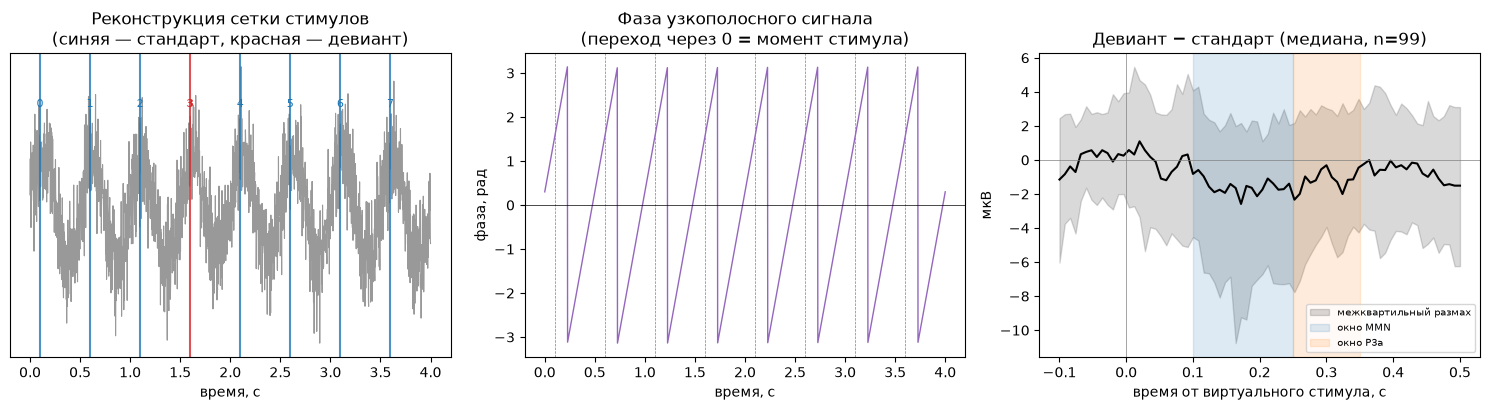

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

t = np.linspace(0, 4, 2000)
np.random.seed(0)
sig = 0.3 * np.sin(2 * np.pi * 2.0 * t) + 0.15 * np.random.randn(len(t))
stim_t = np.arange(0.1, 4, 0.5)
deviant_idx = 3
axes[0].plot(t, sig, color="0.6", lw=0.8)
for i, st in enumerate(stim_t):
    pos = i % 8
    color = "tab:red" if i == deviant_idx else "tab:blue"
    axes[0].axvline(st, color=color, lw=1.5, alpha=0.8)
    axes[0].text(st, 0.55, str(pos), ha="center", fontsize=8,
                 color=color, fontweight="bold" if i == deviant_idx else "normal")
axes[0].set_title("Реконструкция сетки стимулов\n(синяя — стандарт, красная — девиант)")
axes[0].set_xlabel("время, с")
axes[0].set_yticks([])

phase_demo = np.angle(np.exp(1j * 2 * np.pi * 2.0 * t) * np.exp(1j * 0.3))
axes[1].plot(t, phase_demo, color="tab:purple", lw=1)
for st in stim_t:
    axes[1].axvline(st, color="gray", lw=0.5, ls="--")
axes[1].axhline(0, color="k", lw=0.5)
axes[1].set_title("Фаза узкополосного сигнала\n(переход через 0 = момент стимула)")
axes[1].set_xlabel("время, с")
axes[1].set_ylabel("фаза, рад")

grand_clean = np.median(diff_mat[clean_mask], axis=0)
lo_q = np.percentile(diff_mat[clean_mask], 25, axis=0)
hi_q = np.percentile(diff_mat[clean_mask], 75, axis=0)

axes[2].plot(t_ax, grand_clean, color="k", lw=1.5)
axes[2].fill_between(t_ax, lo_q, hi_q, color="k", alpha=0.15, label="межквартильный размах")
axes[2].axvspan(0.10, 0.25, color="tab:blue", alpha=0.15, label="окно MMN")
axes[2].axvspan(0.25, 0.35, color="tab:orange", alpha=0.15, label="окно P3a")
axes[2].axhline(0, color="gray", lw=0.5)
axes[2].axvline(0, color="gray", lw=0.5)
axes[2].set_title(f"Девиант − стандарт (медиана, n={clean_mask.sum()})")
axes[2].set_xlabel("время от виртуального стимула, с")
axes[2].set_ylabel("мкВ")
axes[2].legend(fontsize=7, loc="lower right")

plt.tight_layout()
plt.savefig(OUT_DIR / "erp_method_result.png", dpi=150)
plt.show()

## Итог

1. Метки стимулов восстановлены из фонового ритма метронома без размеченных событий (узкополосная
   фильтрация + фаза Гильберта, с уточнением реальной частоты и обязательной обрезкой краёв записи от
   переходного процесса фильтра).
2. Положение девианта в цикле по одиночной записи ненадёжно (подтверждено перестановочным тестом), но
   само наличие структуры, привязанной к восстановленной фазе, статистически значимо и воспроизводимо на
   независимой половине данных того же файла (split-half) — метод не является артефактом шума.
3. На уровне группы (после исключения калибровочных выбросов) обнаружена значимая
   негативность в окне MMN (100–250 мс, пик на 150–200 мс).
4. P3a статистически не подтверждён в ожидаемом направлении.
